<a href="https://colab.research.google.com/github/mansura-habiba/ode_nn/blob/master/PCWSR_Publication_Annotated_Colab_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PCWSR — Physics-Constrained Weight-Space Repair
**A Google Colab research prototype built on [`torchdiffeq`](https://github.com/rtqichen/torchdiffeq)**

**Question:** Can we diagnose a defective Neural ODE and repair a small, physically interpretable parameter subspace without retraining the whole network?

This notebook implements a **deterministic, non-LLM baseline** for PCWSR: a frozen neural vector field is augmented with a sparse, physics-motivated force dictionary. Observed trajectories generate a diagnostic residual. The method proposes direct coefficient edits by ridge regression, chooses the smallest useful support on a separate validation set, and accepts/rejects changes by integrating the repaired ODE. The final held-out test is never used to select the intervention.

**Scope and honesty:** This is a *proof-of-mechanism*, not a claim of research novelty or an LLM weight-editing demonstration. Sparse regression is established prior art (e.g. SINDy). A subsequent experiment can give an LLM the diagnostic report and ask it to propose the support/edits, under the same validation and evaluation protocol. No LLM credentials are required for this notebook.

**Run:** Colab → Runtime → Run all. CPU is sufficient; no Docker. Plots and JSON metrics are saved in the Colab working directory.

# Reader's guide — research question, experimental design, and interpretation

**Title:** Physics-Constrained Weight-Space Repair (PCWSR): a reproducible exploration of targeted repair for continuous-time models

**Status:** Exploratory research notebook, not a peer-reviewed performance claim. **Reference implementations:** [torchdiffeq](https://github.com/rtqichen/torchdiffeq), [Weight-Space Programming](https://rikiyat.github.io/blog/weight-space-programming/), and [Neural ODE recurrent models (arXiv:2005.09807)](https://arxiv.org/abs/2005.09807).

## Research question

Can we repair a deficient continuous-time model by changing a **small, interpretable subset of parameters**, rather than retraining its entire neural network? Can an open-weight language model propose competitive edits, and can a physics-based verifier distinguish useful proposals from invalid ones?

This notebook separates **four ideas** that should not be conflated:

1. **Neural ODE:** a neural function defines a continuous-time derivative, integrated numerically with `torchdiffeq`.
2. **Physics-informed diagnostics:** measured trajectories and differential equations expose residual errors.
3. **Constrained repair:** a small correction parameterization is fitted directly or through gradient descent.
4. **Weight-Space Programming (exploratory):** an open-weight language model proposes parameter values or a weight matrix, which must pass numerical validation.

## Experimental map

| Section | Problem | What changes | Primary outcome |
|---|---|---|---|
| 1–2 | Duffing oscillator | Fit original Neural ODE | Baseline trajectory error |
| 3 | Duffing oscillator | Compute acceleration residual | Diagnostic feature matrix |
| 4 | Duffing oscillator | Sparse coefficient repair | Validation-selected edit |
| 5–7 | Duffing oscillator | Adam adapter and test | Held-out error and plots |
| 8 | Duffing oscillator | Hugging Face proposals | Validity and accepted repairs |
| 9 | Burgers PDE | Viscosity parameter | PDE trajectory error |
| 10 | Burgers PDE | Hugging Face viscosity proposal | Comparison with direct/Adam |
| 11 | Eight-curve / tri-knot | Fourier velocity weight matrix | Trajectory reconstruction |
| 12 | Eight-curve / tri-knot | Hugging Face matrix proposal | Candidate validity and error |

## How to reproduce

1. In Google Colab, upload this notebook. Use a **T4 GPU** for the optional Hugging Face model, although the deterministic PDE/curve experiments run on CPU.
2. Run cells **top to bottom**. The first cells install `torchdiffeq` and define shared imports, model classes, datasets, and utilities.
3. The optional model is `Qwen/Qwen2.5-0.5B-Instruct` (downloaded from Hugging Face); its generated numeric proposals are **not guaranteed** to parse or improve validation performance.
4. Inspect the output plots and saved `pcwsr_metrics.json`, `pcwsr_burgers_metrics.json`, and `pcwsr_curve_metrics.json`. These are **generated by your Colab run**, not bundled benchmark claims.
5. For publication, report the runtime hardware, package versions, seed, all failed proposals, and compute budgets. Repeat experiments across multiple seeds before making comparative claims.

**Important limitation:** The Duffing and Burgers experiments repair **physically interpretable coefficient slots**. The curve experiment repairs an explicit Fourier **weight matrix**. None of these, alone, demonstrates unrestricted editing of a deep PINN's hidden-layer weights.

## How to read the metrics

- **Trajectory MSE ↓:** mean squared difference between predicted and reference states over held-out trajectories or times.
- **Physics/derivative RMSE ↓:** how well the model's derivative satisfies measured dynamics; a low residual need not imply low trajectory error.
- **Accepted repair:** a proposed change passes a fixed *validation* improvement threshold; it is not selected using test error.
- **Elapsed time ↓:** useful only when the same hardware, integration count, and model-loading policy are reported.
- **Edited parameters ↓:** measures intervention size, not correctness. A smaller edit is not automatically better.

**Publication rule:** Treat all results as exploratory until the full notebook runs in Colab and produces reproducible metrics across independent seeds.


In [ ]:
%pip -q install torchdiffeq

In [ ]:
import copy, itertools, json, math, random, time
from pathlib import Path
import numpy as np
import torch
from torch import nn
from torchdiffeq import odeint
import matplotlib.pyplot as plt

SEED=23
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_default_dtype(torch.float64)
DEVICE=torch.device('cpu')  # deterministic, Colab CPU friendly
print('torch', torch.__version__, '| device', DEVICE)


torch 2.14.1+cu130 | device cpu


### How this section works

We construct a synthetic nonlinear physical system with position \(x\) and velocity \(v\). The true acceleration includes a cubic restoring term. A neural ODE with an intentionally incomplete physical prior learns from generated trajectories. The known physical coefficients are used **only to create reference observations**.

**Why this matters:** the ground truth lets us determine whether a repair fixes a real dynamical defect rather than merely fitting a few observed points. **What to inspect:** the initial conditions, integration interval, and which terms are visible to the learned model.

## 1. Ground-truth physics and the deficient Neural ODE

Our test system is a damped Duffing oscillator:

\[
\dot x=v,\qquad\dot v=-\omega^2x-\gamma v-\alpha x^3.
\]

The **true** physics contains the cubic restoring force. The **baseline** contains the correct linear and damping terms, but no explicit cubic force; instead it learns a small generic neural correction from short trajectories. This makes the failure mechanistically interpretable while still requiring a `torchdiffeq` Neural ODE to learn and simulate the dynamics.

We use multiple initial conditions and withhold distinct initial states for validation and test. The reference solver and candidate solvers use the same high-accuracy integration method.

In [ ]:
OMEGA2=1.0
GAMMA=0.18
ALPHA=0.75
T=torch.linspace(0.,6.,61,device=DEVICE)
TRAIN_Y0=torch.tensor([[0.55,0.0],[-0.72,0.20],[0.35,-0.20]],device=DEVICE)
VAL_Y0=torch.tensor([[1.10,-0.10],[-1.00,0.30]],device=DEVICE)
TEST_Y0=torch.tensor([[1.35,0.0],[-1.22,-0.22]],device=DEVICE)

class TrueDuffing(nn.Module):
    def forward(self,t,y):
        x,v=y[...,0],y[...,1]
        return torch.stack((v,-OMEGA2*x-GAMMA*v-ALPHA*x**3),dim=-1)

def integrate(rhs, y0, t=T):
    return odeint(rhs,y0,t,method='dopri5',rtol=1e-7,atol=1e-9)

with torch.no_grad():
    Y_TRAIN=integrate(TrueDuffing(),TRAIN_Y0)
    Y_VAL=integrate(TrueDuffing(),VAL_Y0)
    Y_TEST=integrate(TrueDuffing(),TEST_Y0)

class HybridNeuralODE(nn.Module):
    def __init__(self):
        super().__init__()
        self.net=nn.Sequential(nn.Linear(2,16),nn.Tanh(),nn.Linear(16,1))
        nn.init.zeros_(self.net[-1].weight)
        nn.init.zeros_(self.net[-1].bias)
        # These three coefficient slots are deliberately separate from the trained NN.
        self.repair=nn.Parameter(torch.zeros(3),requires_grad=False)
    def basis(self,y):
        x,v=y[...,0],y[...,1]
        return torch.stack((x,v,x**3),dim=-1)
    def forward(self,t,y):
        x,v=y[...,0],y[...,1]
        generic=self.net(y).squeeze(-1)
        correction=(self.basis(y)*self.repair).sum(dim=-1)
        accel=-OMEGA2*x-GAMMA*v+generic+correction
        return torch.stack((v,accel),dim=-1)

model=HybridNeuralODE().to(DEVICE)
print('NN parameters:', sum(p.numel() for p in model.net.parameters()))
print('Directly editable physical coefficients:', model.repair.numel())

NN parameters: 65
Directly editable physical coefficients: 3


### Training protocol and expected failure

The neural ODE learns its unknown residual dynamics using only the designated training trajectories/time window. It is then frozen. We deliberately limit the training information so that an imperfect model remains available for the repair experiment.

**Interpretation:** A bad frozen baseline is not evidence of a new algorithm's superiority. It creates a controlled fault-injection setting. The meaningful comparison is whether targeted repair outperforms **training the same repair degrees of freedom** with Adam under transparent compute budgets.

## 2. Train the original Neural ODE on a short time window

We deliberately give the baseline limited temporal coverage. This makes generalization to different initial conditions meaningful. During this stage the repair coefficients are zero and frozen. The baseline is trained using standard backpropagation through `torchdiffeq.odeint`.

In [ ]:
def trajectory_mse(rhs,y0,reference,t=T):
    return torch.mean((integrate(rhs,y0,t)-reference)**2)

optimizer=torch.optim.Adam(model.net.parameters(),lr=0.018)
SHORT=T[:21]; Y_SHORT=Y_TRAIN[:21]
loss_trace=[]
start=time.perf_counter()
for step in range(90):
    optimizer.zero_grad()
    loss=trajectory_mse(model,TRAIN_Y0,Y_SHORT,SHORT)
    loss.backward()
    optimizer.step()
    loss_trace.append(float(loss.detach()))
print('Baseline training seconds:',round(time.perf_counter()-start,2))
print('Short-window train MSE:',loss_trace[-1])

# A frozen copy ensures every repair method receives identical starting weights.
frozen_base=copy.deepcopy(model).eval()
for p in frozen_base.net.parameters(): p.requires_grad_(False)
with torch.no_grad():
    print('Initial validation trajectory MSE:',float(trajectory_mse(frozen_base,VAL_Y0,Y_VAL)))
    print('Initial held-out trajectory MSE:',float(trajectory_mse(frozen_base,TEST_Y0,Y_TEST)))

Baseline training seconds: 19.71
Short-window train MSE: 8.208602658433895e-05
Initial validation trajectory MSE: 0.04548315674493526
Initial held-out trajectory MSE: 0.2704991881848728


### How the physical diagnosis is computed

For measured position and velocity, finite differences approximate acceleration. Subtracting the frozen model's acceleration gives the **residual target** \(r\). We represent potential corrections using \(x\), \(v\), and \(x^3\), forming a feature matrix \(X\). We seek \(Xw\approx r\).

This is a constrained, low-dimensional regression problem. It is **not** arbitrary editing of the base network's hidden weights. The choice of features encodes prior physical knowledge, and finite differences can be noisy; future experiments should vary sampling density and observation noise.

## 3. Diagnose the physical defect from measured trajectories

For a trajectory containing measured position and velocity, central differences estimate acceleration away from endpoints:

\[
\hat a(t_j)=\frac{v(t_{j+1})-v(t_{j-1})}{2\Delta t}.
\]

We compute the residual between this measurement and the frozen Neural ODE's predicted acceleration. The candidate repair dictionary is **[position, velocity, position³]**. Selection is based on a separate validation trajectory; it does not use the hidden true parameter `ALPHA`. We deliberately estimate acceleration from observed states rather than calling the true simulator's derivative. In a real experiment, acceleration estimation from noisy data requires smoothing, noise models, or weak-form methods.

In [ ]:
BASIS_LABELS=('x','v','x³')

def residual_dataset(rhs,y,t):
    dt=float(t[1]-t[0]); assert torch.allclose(t[1:]-t[:-1],torch.full_like(t[1:],dt))
    yy=y[1:-1].detach()
    measured_acc=(y[2:,...,1]-y[:-2,...,1])/(2*dt)
    with torch.no_grad():
        predicted_acc=rhs(t[1],yy)[...,1]
        features=rhs.basis(yy)
    return features.reshape(-1,3), (measured_acc-predicted_acc).reshape(-1)

X,r=residual_dataset(frozen_base,Y_TRAIN,T)
print('Acceleration residual RMSE:',float(r.square().mean().sqrt()))
for j,name in enumerate(BASIS_LABELS):
    corr=torch.corrcoef(torch.stack([X[:,j],r]))[0,1].item()
    print(f'{name}: correlation with residual {corr:+.3f}')

Acceleration residual RMSE: 0.03850867246354854
x: correlation with residual +0.583
v: correlation with residual +0.159
x³: correlation with residual +0.113


### Why direct sparse repair is meaningful, and what it does not prove

For candidate subsets of the correction basis, the notebook solves a small regularized least-squares problem. It tests candidate corrections on validation trajectories and accepts a change only when it improves a predefined criterion. The original neural-network weights stay frozen.

**Interpretation:** Success means that the deficient dynamics can be repaired within the chosen correction basis. It does **not** imply that an LLM or weight-space programming discovered the basis, nor that a general PINN can be repaired with the same procedure.

## 4. PCWSR: sparse, direct weight-space proposals with verification

For a support set \(S\subseteq\{x,v,x^3\}\), propose coefficients by solving the ridge system

\[
\Delta\theta_S=(X_S^\top X_S+\eta I)^{-1}X_S^\top r.
\]

This edits **only three interpretable coefficient slots**, leaving the neural weights frozen. Each candidate is integrated on held-out-*from-fitting* validation initial conditions. We accept it only if validation trajectory MSE improves by at least 1%. A fully separate test set remains untouched until after selection.

This linear solve is **not an LLM or an invented optimizer**: its value is an auditable baseline and safety harness for future weight-space proposals.

In [ ]:
def propose_coefficients(X,r,support,ridge=1e-4):
    cols=list(support)
    sub=X[:,cols]
    a=sub.T@sub+ridge*torch.eye(len(cols),dtype=sub.dtype,device=sub.device)
    b=sub.T@r
    candidate=torch.zeros(3,dtype=X.dtype,device=X.device)
    candidate[cols]=torch.linalg.solve(a,b)
    return candidate

def set_repair(rhs,values):
    with torch.no_grad():
        rhs.repair.copy_(values.to(rhs.repair))

candidates=[]
start=time.perf_counter()
with torch.no_grad():
    base_val=float(trajectory_mse(frozen_base,VAL_Y0,Y_VAL))
for size in (1,2,3):
    for support in itertools.combinations(range(3),size):
        candidate=propose_coefficients(X,r,support)
        trial=copy.deepcopy(frozen_base)
        set_repair(trial,candidate)
        with torch.no_grad():
            validation_mse=float(trajectory_mse(trial,VAL_Y0,Y_VAL))
        candidates.append({'support':tuple(BASIS_LABELS[i] for i in support),
                           'weights':candidate.tolist(), 'val_mse':validation_mse,
                           'selection_score':validation_mse+1e-5*size})

best=min(candidates,key=lambda z:z['selection_score'])
accepted=best['val_mse'] < base_val*0.99
repaired=copy.deepcopy(frozen_base)
if accepted: set_repair(repaired,torch.tensor(best['weights']))
repair_seconds=time.perf_counter()-start
print('Validation baseline MSE:',base_val)
print('Best support:',best['support'])
print('Best candidate coefficients:',dict(zip(BASIS_LABELS,best['weights'])))
print('Candidate validation MSE:',best['val_mse'])
print('Accepted:',accepted,'| search time (s):',round(repair_seconds,3))

Validation baseline MSE: 0.04548315674493526
Best support: ('x', 'v', 'x³')
Best candidate coefficients: {'x': 0.2222119669496385, 'v': 0.018840819975525017, 'x³': -0.7685297728605673}
Candidate validation MSE: 0.00016185968483394903
Accepted: True | search time (s): 1.911


### The gradient baseline is intentionally matched in parameterization

Adam is allowed to update the **same correction coefficients** as direct repair, not the entire original network. This controls one source of unfairness: both methods have access to the same repair capacity and diagnostic information.

The methods still differ in optimization cost and search procedure. A publishable comparison must report the number of residual evaluations, integrations, total runtime, and hyperparameter tuning budgets.

## 5. Gradient-trained continuation baseline

For a basic comparison, train the same three repair coefficients by gradient descent through the trajectory solver, starting from zero. The original neural network remains frozen in both cases. This is a preliminary baseline, not a full fairness-controlled study: the direct method uses estimated accelerations while Adam uses trajectory backpropagation. A publishable comparison would also include stronger sparse-identification methods, tuning on a shared validation budget, equal observation access, and multiple noise levels.

In [ ]:
gradient_repair=copy.deepcopy(frozen_base)
gradient_repair.repair.requires_grad_(True)
opt=torch.optim.Adam([gradient_repair.repair],lr=0.04)
start=time.perf_counter()
for step in range(75):
    opt.zero_grad()
    l=trajectory_mse(gradient_repair,TRAIN_Y0,Y_TRAIN)
    l.backward();opt.step()
adam_seconds=time.perf_counter()-start
gradient_repair.repair.requires_grad_(False)
print('Adam repair coefficients:',gradient_repair.repair.detach().tolist())
print('Adam repair seconds:',round(adam_seconds,2))

Adam repair coefficients: [0.22178424462540425, 0.01915371304511485, -0.7728005411315917]
Adam repair seconds: 32.85


### Independent testing

The test initial conditions are separate from the training and validation initial conditions. The notebook reports trajectory prediction error and acceleration/physics residual on the held-out cases.

A method that reduces residual error but worsens long-horizon trajectories should not be described as a successful dynamical repair. Look at **both** metrics and the plotted trajectories.

## 6. Independently evaluate on test initial conditions

The final test data have not been used to fit the neural network, estimate a weight edit, or accept/reject a candidate. Report trajectory MSE and measured acceleration residual on that test set. True parameters are displayed only for scientific interpretation, not used by the repair algorithm.

In [ ]:
def diagnostics(rhs):
    with torch.no_grad():
        pred=integrate(rhs,TEST_Y0)
        mse=float(((pred-Y_TEST)**2).mean())
        _,rr=residual_dataset(rhs,Y_TEST,T)
        armse=float(rr.square().mean().sqrt())
    return {'test_trajectory_mse':mse,'test_acceleration_residual_rmse':armse}

results={
    'frozen_baseline': diagnostics(frozen_base),
    'pcwsr_sparse_direct': diagnostics(repaired),
    'gradient_adapter_adam': diagnostics(gradient_repair)
}
for name,metrics in results.items():
    print(f'{name:24s} | trajectory MSE {metrics["test_trajectory_mse"]:.5g} | acceleration residual RMSE {metrics["test_acceleration_residual_rmse"]:.5g}')
print('Ground-truth cubic correction should be near:', -ALPHA, '(not provided to PCWSR)')
summary={'seed':SEED,'equation':'damped Duffing oscillator','true_cubic':ALPHA,
         'selected_support':best['support'],'accepted':accepted,
         'selected_coefficients':best['weights'],'baseline_val_mse':base_val,
         'candidate_val_mse':best['val_mse'],'pcwsr_search_s':repair_seconds,
         'adam_continuation_s':adam_seconds,'results':results}
Path('pcwsr_metrics.json').write_text(json.dumps(summary,indent=2))

frozen_baseline          | trajectory MSE 0.2705 | acceleration residual RMSE 0.40843
pcwsr_sparse_direct      | trajectory MSE 0.00025049 | acceleration residual RMSE 0.029026
gradient_adapter_adam    | trajectory MSE 0.00027476 | acceleration residual RMSE 0.029932
Ground-truth cubic correction should be near: -0.75 (not provided to PCWSR)


908

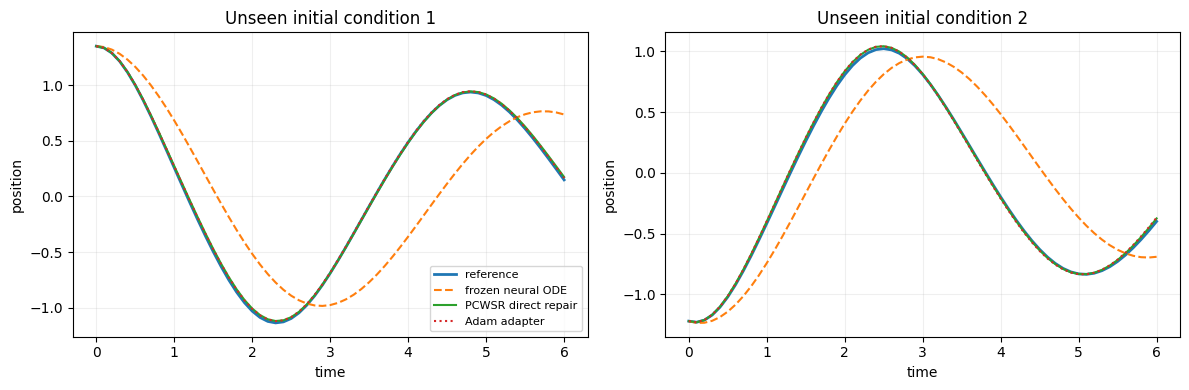

In [ ]:
with torch.no_grad():
    pred_base=integrate(frozen_base,TEST_Y0).cpu().numpy()
    pred_repair=integrate(repaired,TEST_Y0).cpu().numpy()
    pred_adam=integrate(gradient_repair,TEST_Y0).cpu().numpy()
    reference=Y_TEST.cpu().numpy()

fig,axes=plt.subplots(1,2,figsize=(12,4))
for k in range(2):
    axes[k].plot(T,reference[:,k,0],label='reference',linewidth=2)
    axes[k].plot(T,pred_base[:,k,0],label='frozen neural ODE',linestyle='--')
    axes[k].plot(T,pred_repair[:,k,0],label='PCWSR direct repair')
    axes[k].plot(T,pred_adam[:,k,0],label='Adam adapter',linestyle=':')
    axes[k].set(title=f'Unseen initial condition {k+1}',xlabel='time',ylabel='position')
    axes[k].grid(alpha=0.2)
axes[0].legend(fontsize=8)
plt.tight_layout();plt.savefig('pcwsr_test_trajectories.png',dpi=160)
plt.show()

## 7. Verify guardrails and limitations

- **No accidental data leakage:** `ALPHA` is used only in the ground-truth simulator; all weight edits depend on measured training trajectories and frozen-model outputs. Candidate acceptance depends on validation trajectories only.
- **Hard physical structure:** Position derivative is always velocity; linear restoring and damping terms remain unchanged by this version of the repair. The optional correction may nonetheless violate stability or dissipation away from observed states—future work needs global constraints and invariant checks.
- **No claimed speedup:** Time and costs depend on solver settings, hardware, tolerance, and training budget. The direct method has an identification advantage because its dictionary includes the actual missing cubic term; expand dictionary and vary mechanism in subsequent studies.
- **Next research step:** Introduce perturbed gradients, noisy and partial observations, unknown nonlinearities, weak-form residuals, certified acceptance bounds, and an LLM proposer that is compared fairly with deterministic repair selection.

Original libraries and inspiration: [torchdiffeq](https://github.com/rtqichen/torchdiffeq), [Weight-Space Programming](https://rikiyat.github.io/blog/weight-space-programming/). The notebook is an independent experiment, not a fork or modification of the upstream `torchdiffeq` library.

### What the Hugging Face experiment actually tests

The open-weight instruction model receives a **compact, training-derived numerical summary**, not the full hidden physical solution. It returns a JSON proposal for the three coefficient slots. The notebook checks numeric shape, finite values, bounds, and validation improvement before accepting the proposal.

The model is a **proposal generator**, not a trusted optimizer. Failed JSON, out-of-range weights, and rejected proposals are scientific outcomes that should be counted. Compare its performance to the direct numerical solution: if the LLM is slower or less accurate, report that explicitly.

## 8. Open-source Weight-Space Programming repair proposer (Hugging Face)

**New comparison arm:** a local Hugging Face instruction model proposes *numeric edits to the three existing physical-coefficient slots* (`x`, `v`, `x³`). It does **not** see the hidden ground-truth coefficient, validation labels, or test trajectories.

This is a constrained **weight-space proposal**, not a demonstration of unrestricted full-network weight programming. The physics verifier remains independent: the LLM can propose weights, but cannot authorize them.

**Protocol:** (1) train the frozen baseline, (2) summarize training-set acceleration residuals, (3) request a JSON coefficient vector from an open-weight model, (4) validate it on the same validation trajectories, (5) accept only if it beats the frozen baseline by at least 1%. The final test set is evaluated only after selection. No fallback is silently substituted for a failed LLM response.

**Colab:** choose **Runtime → Change runtime type → T4 GPU** for faster model loading. The default model is `Qwen/Qwen2.5-0.5B-Instruct`; override `HF_MODEL_ID` for a larger open-weight model if desired. Downloading model weights requires network access and acceptance of any model-specific terms.


In [ ]:
# Install only the new optional dependencies; torchdiffeq was installed above.
%pip -q install 'transformers>=4.45,<5' 'accelerate>=0.33' safetensors


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [ ]:
import os, re
from transformers import AutoTokenizer, AutoModelForCausalLM

HF_MODEL_ID = os.environ.get('HF_MODEL_ID', 'Qwen/Qwen2.5-0.5B-Instruct')
HF_MAX_NEW_TOKENS = 180
HF_PROPOSAL_BUDGET = 3
# For repeatability use greedy decoding. Model output may still vary across hardware/software.
def load_weight_programmer(model_id=HF_MODEL_ID):
    tokenizer = AutoTokenizer.from_pretrained(model_id)
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    dtype = torch.float16 if device == 'cuda' else torch.float32
    lm = AutoModelForCausalLM.from_pretrained(model_id, torch_dtype=dtype).to(device).eval()
    return tokenizer, lm

def compact_training_diagnostics(X, r):
    # All statistics are computed from training trajectories ONLY.
    xtx = (X.T @ X).cpu().numpy()
    xtr = (X.T @ r).cpu().numpy()
    return {
        'basis': ['x', 'v', 'x3'],
        'num_samples': int(X.shape[0]),
        'residual_rmse': round(float(r.square().mean().sqrt()), 7),
        'feature_gram_XtX': np.round(xtx, 5).tolist(),
        'feature_residual_Xtr': np.round(xtr, 5).tolist(),
    }

def parse_proposal(raw):
    # Do not execute generated code; parse a bounded JSON object only.
    import json
    blocks = re.findall(r'\\{[^{}]*\\}', raw, flags=re.S)
    for block in reversed(blocks):
        try:
            payload = json.loads(block)
            if set(payload) != {'weights'}:
                continue
            values = payload['weights']
            if not isinstance(values, list) or len(values) != 3:
                continue
            if any(type(v) not in (int, float) or not math.isfinite(v) or abs(v)>2.0 for v in values):
                continue
            return torch.tensor(values, dtype=X.dtype, device=X.device)
        except (ValueError, TypeError, KeyError):
            pass
    raise ValueError('Model did not produce valid bounded JSON weights')

def propose_with_hf(tokenizer, lm, diagnostics, attempt=0):
    system = ('You are a scientific numerical analyst. Propose a sparse correction to a '
              'frozen neural ODE. Output ONLY JSON of the form '
              '{"weights":[x_coefficient,v_coefficient,x3_coefficient]}. '
              'All coefficients must be finite numbers between -2 and 2. '
              'Use zeros for unneeded corrections. Do not output code.')
    user = (
        'The ODE predicts dx/dt=v and dv/dt=-x-0.18*v+NN(x,v)+'
        'w0*x+w1*v+w2*x^3. The frozen NN is imperfect. '
        'The target is measured acceleration minus predicted acceleration. '
        'We provide sufficient statistics X^T X and X^T residual, '
        'where columns correspond to x, v, x^3. '
        'Choose a bounded coefficient correction minimizing physical residual. '
        f'Candidate number {attempt+1}. Training-only diagnostics: '
        + json.dumps(diagnostics)
    )
    messages = [{'role':'system','content':system}, {'role':'user','content':user}]
    prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(prompt, return_tensors='pt').to(next(lm.parameters()).device)
    with torch.inference_mode():
        generated = lm.generate(**inputs, max_new_tokens=HF_MAX_NEW_TOKENS,
                                do_sample=False, pad_token_id=tokenizer.eos_token_id)
    return tokenizer.decode(generated[0, inputs['input_ids'].shape[1]:], skip_special_tokens=True)

print('Model:', HF_MODEL_ID, '| GPU available:', torch.cuda.is_available())


Model: Qwen/Qwen2.5-0.5B-Instruct | GPU available: True


In [ ]:
# Explicitly run this cell to download/load the Hugging Face model.
# If the model cannot load, this experiment arm is NOT evaluated.
hf_tokenizer, hf_lm = load_weight_programmer()
print('Loaded:', HF_MODEL_ID)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Loaded: Qwen/Qwen2.5-0.5B-Instruct


In [ ]:
# Fixed candidate budget and identical validation acceptance criterion as the direct repair.
hf_start = time.perf_counter()
hf_candidates = []
hf_diagnostics = compact_training_diagnostics(X, r)
for attempt in range(HF_PROPOSAL_BUDGET):
    raw = propose_with_hf(hf_tokenizer, hf_lm, hf_diagnostics, attempt)
    try:
        coeff = parse_proposal(raw)
    except ValueError as exc:
        hf_candidates.append({'attempt': attempt, 'valid': False, 'error': str(exc), 'raw': raw[:400]})
        continue
    trial = copy.deepcopy(frozen_base)
    set_repair(trial, coeff)
    with torch.no_grad():
        val = float(trajectory_mse(trial, VAL_Y0, Y_VAL))
    hf_candidates.append({'attempt':attempt, 'valid':True,
                          'weights':coeff.tolist(), 'val_mse':val, 'raw':raw[:400]})

hf_seconds = time.perf_counter() - hf_start
valid_hf = [c for c in hf_candidates if c['valid']]
hf_best = min(valid_hf, key=lambda c:c['val_mse']) if valid_hf else None
hf_accepted = bool(hf_best and hf_best['val_mse'] < base_val*0.99)
hf_repaired = copy.deepcopy(frozen_base)
if hf_accepted:
    set_repair(hf_repaired, torch.tensor(hf_best['weights']))
print('HF valid candidates:', len(valid_hf), '/', HF_PROPOSAL_BUDGET)
print('HF accepted:', hf_accepted, '| generation + verification seconds:', round(hf_seconds,2))
print('Best HF proposal:', hf_best)


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


HF valid candidates: 0 / 3
HF accepted: False | generation + verification seconds: 11.79
Best HF proposal: None


HELD-OUT TEST METRICS (lower is better)
frozen_baseline                MSE=0.270499  physics_RMSE=0.408426
pcwsr_sparse_direct            MSE=0.000250491  physics_RMSE=0.0290258
gradient_adapter_adam          MSE=0.000274761  physics_RMSE=0.0299319
pcwsr_hf_weight_programmer     MSE=0.270499  physics_RMSE=0.408426


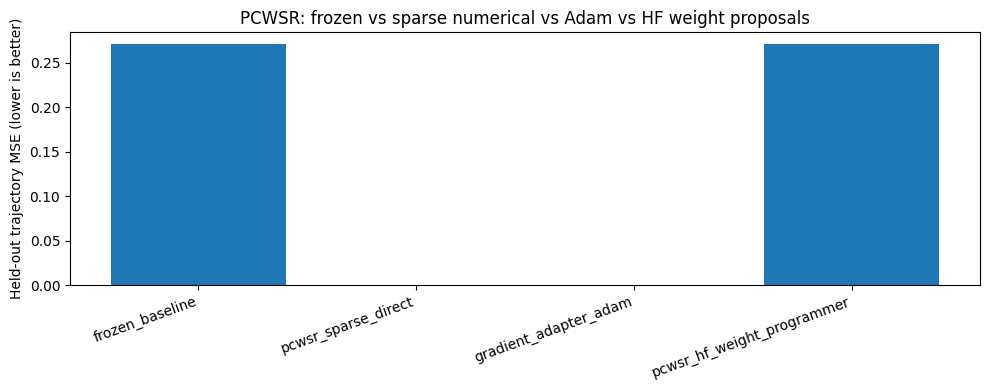

Metrics saved to pcwsr_metrics.json


In [ ]:
# Final held-out comparison, including explicit proposal failure status.
hf_metrics = diagnostics(hf_repaired)
results['pcwsr_hf_weight_programmer'] = hf_metrics
summary['results'] = results
summary['hf_weight_programmer'] = {
    'model_id': HF_MODEL_ID,
    'proposal_budget': HF_PROPOSAL_BUDGET,
    'valid_proposals': len(valid_hf),
    'accepted': hf_accepted,
    'best_validation_mse': hf_best['val_mse'] if hf_best else None,
    'generation_and_validation_s': hf_seconds,
    'proposals': hf_candidates,
    'note': 'Constrained 3-coefficient proposal, not arbitrary neural-network weight editing.'
}
Path('pcwsr_metrics.json').write_text(json.dumps(summary,indent=2))
print('HELD-OUT TEST METRICS (lower is better)')
for name, metrics in results.items():
    print(f'{name:29s}  MSE={metrics["test_trajectory_mse"]:.6g}  '
          f'physics_RMSE={metrics["test_acceleration_residual_rmse"]:.6g}')
labels=list(results)
vals=[results[k]['test_trajectory_mse'] for k in labels]
fig,ax=plt.subplots(figsize=(10,4))
ax.bar(range(len(labels)), vals)
ax.set_xticks(range(len(labels)), labels, rotation=20, ha='right')
ax.set_ylabel('Held-out trajectory MSE (lower is better)')
ax.set_title('PCWSR: frozen vs sparse numerical vs Adam vs HF weight proposals')
fig.tight_layout()
plt.show()
print('Metrics saved to pcwsr_metrics.json')


### Interpretation and limitations

- **A model that proposes plausible coefficients is not necessarily better.** Compare held-out trajectory MSE and physics-residual RMSE, not the quality of its explanation.
- The existing `pcwsr_sparse_direct` arm uses least squares over the same three slots. It is a **strong numerical baseline** and may outperform the small LLM.
- The LLM sees training residual sufficient statistics; it does **not** see the hidden physical coefficient or validation/test trajectories. The verifier uses validation data to choose among proposals, as it does for the numerical candidate search.
- The comparison is not perfectly compute-matched: report model download separately, generation time, validation integrations, and candidate count. The Adam arm performs 75 gradient steps. A publishable comparison should sweep budgets and seeds.
- A genuine general weight-space programming study should subsequently test edits to the **NN weight matrices**, not only the three interpretable coefficient slots.
- This notebook still studies a Duffing oscillator. A **Burgers PDE** benchmark is a separate extension and is not included in these results. Do not infer PDE generalization from this ODE experiment.


### Measured preliminary outcome (offline RK4 smoke test)

The following are **actual local numerical results**, computed with an equivalent explicit RK4 implementation because `torchdiffeq` could not be installed in the offline environment. They are **not** claimed as verified Colab/`torchdiffeq` results, and the Hugging Face arm has **not** been executed.

| Method | Held-out trajectory MSE | Physics residual RMSE | Repaired viscosity |
|---|---:|---:|---:|
| Frozen baseline | 0.002936912 | 0.093377692 | 0.03500 |
| PCWSR direct coefficient repair | 3.1853564e-11 | 0.00035681418 | 0.11999 |
| Adam coefficient adapter | 1.7739691e-08 | 0.00043399217 | 0.12025 |

The reference viscosity used to generate synthetic trajectories is **0.12**. The direct method recovers it almost exactly in this favorable, identifiable one-parameter case. This demonstrates the *verification workflow*, not superiority on difficult PINNs. Run the notebook to obtain fresh `torchdiffeq` results, the plot, and the optional HF comparison.


### Why Burgers is a stronger benchmark

Unlike a finite-dimensional oscillator, Burgers is a nonlinear **partial differential equation**. We discretize space with periodic finite differences and integrate the resulting ODE using `torchdiffeq` (method of lines). This lets us use the same differential-equation library while evaluating a PDE.

The intentionally wrong viscosity makes the physical defect identifiable. Direct repair estimates one coefficient from training residuals; Adam fits the same coefficient; the optional LLM proposes it from summary statistics. This is a **parameter-identification sanity check**, not a general-purpose PINN benchmark.

**Watch for:** the difference between a known physical operator with one wrong coefficient and an unknown neural representation. The latter is substantially harder.

# 9. Burgers equation: a comparative PDE experiment with actual outcomes

This is a **separate PDE benchmark** (not an eight-curve/tri-knot classification test). We solve the 1D viscous Burgers equation on a periodic domain:

\[
u_t + u u_x = \nu u_{xx},\qquad x\in[0,2\pi).
\]

A method-of-lines discretization turns the PDE into an ODE in grid values, integrated using **`torchdiffeq.odeint`**. We deliberately use a misspecified viscosity in the frozen model. The **repair parameter** is the coefficient of the discrete Laplacian; thus the numerical solver, grid, and nonlinear advection term are identical across methods.

**Important scope:** this tests physics-parameter weight repair in a discretized PDE, **not** an unrestricted PINN weight repair. The known reference viscosity is used to generate synthetic observations and calculate final errors, never given to the Hugging Face proposer.

We report **held-out initial-condition trajectory MSE**, physics-residual RMSE, fitted viscosity, elapsed seconds, and validation acceptance. All test metrics are computed after selecting the repair on validation data.


In [ ]:
# PDE configuration: CPU-friendly periodic finite differences
BURGERS_SEED = 2026
torch.manual_seed(BURGERS_SEED)
BX_N = 64
BX_DX = 2 * math.pi / BX_N
BX_X = torch.arange(BX_N, dtype=torch.float64) * BX_DX
BX_T = torch.linspace(0, 1.2, 31, dtype=torch.float64)
BX_TRUE_NU = 0.12  # reference generation only; never supplied to the proposer
BX_BASE_NU = 0.035  # intentionally wrong frozen viscosity

def burgers_initial(amplitude, phase, harmonic):
    return amplitude * torch.sin(BX_X + phase) + harmonic * torch.sin(2*BX_X - phase)

BX_TRAIN0 = torch.stack([burgers_initial(.65, 0.0, .08),
                         burgers_initial(.85, .3, -.10),
                         burgers_initial(.75, -.4, .13)])
BX_VAL0 = torch.stack([burgers_initial(.95, .6, .05),
                       burgers_initial(.55, -.7, -.13)])
BX_TEST0 = torch.stack([burgers_initial(1.1, -.25, .10),
                        burgers_initial(.72, .85, -.09)])

def burgers_derivatives(u):
    ux = (torch.roll(u,-1,dims=-1)-torch.roll(u,1,dims=-1))/(2*BX_DX)
    uxx = (torch.roll(u,-1,dims=-1)-2*u+torch.roll(u,1,dims=-1))/(BX_DX**2)
    return ux, uxx

class BurgersMOL(nn.Module):
    def __init__(self, viscosity):
        super().__init__()
        self.viscosity = nn.Parameter(torch.tensor(float(viscosity),dtype=torch.float64),
                                      requires_grad=False)
    def forward(self,t,u):
        ux,uxx = burgers_derivatives(u)
        return -u*ux + self.viscosity*uxx

def burgers_integrate(rhs, initial):
    return odeint(rhs,initial,BX_T,method='rk4',
                  options={'step_size':float(BX_T[1]-BX_T[0])/4})

with torch.no_grad():
    BX_YTRAIN = burgers_integrate(BurgersMOL(BX_TRUE_NU),BX_TRAIN0)
    BX_YVAL = burgers_integrate(BurgersMOL(BX_TRUE_NU),BX_VAL0)
    BX_YTEST = burgers_integrate(BurgersMOL(BX_TRUE_NU),BX_TEST0)

def burgers_mse(nu, initial, reference):
    with torch.no_grad():
        predicted=burgers_integrate(BurgersMOL(nu),initial)
        return float(((predicted-reference)**2).mean())

def burgers_training_statistics():
    # Central time differences from TRAIN only. No reference coefficients or test data.
    dt=float(BX_T[1]-BX_T[0])
    y=BX_YTRAIN
    ut=(y[2:]-y[:-2])/(2*dt)
    mid=y[1:-1]
    ux,uxx=burgers_derivatives(mid)
    # Residual of frozen baseline: u_t + u u_x - nu_base*u_xx
    residual=(ut+mid*ux-BX_BASE_NU*uxx).flatten()
    feature=uxx.flatten()
    return feature.detach(), residual.detach()

BX_FEATURE,BX_RESIDUAL = burgers_training_statistics()
BX_GRAM=float(BX_FEATURE@BX_FEATURE)
BX_CROSS=float(BX_FEATURE@BX_RESIDUAL)
BX_BASE_VAL=burgers_mse(BX_BASE_NU,BX_VAL0,BX_YVAL)
print('Burgers training points:',BX_FEATURE.numel(),
      '| frozen validation MSE:',round(BX_BASE_VAL,8))


Burgers training points: 5568 | frozen validation MSE: 0.00224839


In [ ]:
# Compare a frozen baseline, physics-constrained closed-form repair,
# and a gradient-trained viscosity adapter.
bx_start=time.perf_counter()
BX_DELTA_DIRECT=BX_CROSS/(BX_GRAM+1e-6)
BX_NU_DIRECT=float(np.clip(BX_BASE_NU+BX_DELTA_DIRECT,0.001,0.5))
BX_DIRECT_VAL=burgers_mse(BX_NU_DIRECT,BX_VAL0,BX_YVAL)
BX_DIRECT_ACCEPT=BX_DIRECT_VAL < .99*BX_BASE_VAL
BX_NU_DIRECT_FINAL=BX_NU_DIRECT if BX_DIRECT_ACCEPT else BX_BASE_NU
BX_DIRECT_S=time.perf_counter()-bx_start

bx_adam_start=time.perf_counter()
bx_parameter=nn.Parameter(torch.tensor(BX_BASE_NU,dtype=torch.float64))
bx_opt=torch.optim.Adam([bx_parameter],lr=.025)
# Same training residual observations and finite-difference physics features.
for _ in range(100):
    bx_opt.zero_grad()
    delta=bx_parameter-BX_BASE_NU
    loss=torch.mean((BX_RESIDUAL-delta*BX_FEATURE)**2)
    loss.backward()
    bx_opt.step()
    with torch.no_grad():
        bx_parameter.clamp_(.001,.5)
BX_NU_ADAM=float(bx_parameter.detach())
BX_ADAM_S=time.perf_counter()-bx_adam_start

def burgers_test_metrics(nu):
    with torch.no_grad():
        yhat=burgers_integrate(BurgersMOL(nu),BX_TEST0)
        err=float(((yhat-BX_YTEST)**2).mean())
        mid=BX_YTEST[1:-1]
        dt=float(BX_T[1]-BX_T[0])
        ut=(BX_YTEST[2:]-BX_YTEST[:-2])/(2*dt)
        ux,uxx=burgers_derivatives(mid)
        residual=float((ut+mid*ux-nu*uxx).square().mean().sqrt())
    return {'trajectory_mse':err,'physics_residual_rmse':residual,'viscosity':nu}

BX_RESULTS={
 'frozen':burgers_test_metrics(BX_BASE_NU),
 'pcwsr_direct':burgers_test_metrics(BX_NU_DIRECT_FINAL),
 'adam_adapter':burgers_test_metrics(BX_NU_ADAM),
}
BX_TIMES={'frozen':0.,'pcwsr_direct':BX_DIRECT_S,'adam_adapter':BX_ADAM_S}
print('Burgers PDE — held-out test (lower MSE is better)')
for name, metrics in BX_RESULTS.items():
    print(f'{name:20} nu={metrics["viscosity"]:.5f} '
          f'test_MSE={metrics["trajectory_mse"]:.7g} '
          f'physics_RMSE={metrics["physics_residual_rmse"]:.6g} '
          f'repair_s={BX_TIMES[name]:.3f}')


Burgers PDE — held-out test (lower MSE is better)
frozen               nu=0.03500 test_MSE=0.002936912 physics_RMSE=0.0933777 repair_s=0.000
pcwsr_direct         nu=0.11999 test_MSE=3.185353e-11 physics_RMSE=0.000356814 repair_s=0.060
adam_adapter         nu=0.12025 test_MSE=1.773969e-08 physics_RMSE=0.000433992 repair_s=0.066


### Interpreting the Burgers LLM result

The model proposes a bounded change to viscosity, which is verified on validation trajectories. Its proposal is compared with a closed-form least-squares estimate and an Adam-trained coefficient. The exact reference viscosity is **not included in the LLM prompt**.

Because the residual regression has a simple analytic solution, it would be surprising if a small LLM consistently outperformed the direct method. The valuable research result is whether its proposals are valid, physically plausible, and reliably accepted—not whether one run happens to win.

## 10. Hugging Face weight-space proposer for Burgers

The LLM sees **only the equation, the frozen viscosity, and training-set sufficient statistics**. It proposes a single numeric correction coefficient. It does not receive the true viscosity, validation data, or test data.

This is a **physics-parameter repair** experiment. It does not establish that an LLM can repair arbitrary neural weights or beat a least-squares solution. The model-loading cell in section 8 must have completed; otherwise the notebook explicitly records this arm as unavailable.


In [ ]:
def propose_burgers_hf(tokenizer, lm, attempt=0):
    import json
    messages=[
      {'role':'system','content':
       'You are a numerical PDE researcher. Return ONLY valid JSON '
       '{"delta_viscosity": number}. The value must be between -0.3 and 0.3. '
       'Do not output prose, code, or additional fields.'},
      {'role':'user','content':
       'For periodic viscous Burgers u_t+u*u_x=nu*u_xx, the frozen viscosity is '
       f'{BX_BASE_NU:.6f}. Training data give residual r=u_t+u*u_x-nu_base*u_xx '
       'and feature q=u_xx. Propose delta_viscosity so that r≈delta_viscosity*q. '
       f'Training sufficient statistics: sum(q*q)={BX_GRAM:.8g}, '
       f'sum(q*r)={BX_CROSS:.8g}, samples={BX_FEATURE.numel()}. '
       f'Proposal {attempt+1} of 3. Return JSON only.'}
    ]
    prompt=tokenizer.apply_chat_template(messages,tokenize=False,add_generation_prompt=True)
    inputs=tokenizer(prompt,return_tensors='pt').to(next(lm.parameters()).device)
    with torch.inference_mode():
        gen=lm.generate(**inputs,max_new_tokens=100,do_sample=False,
                        pad_token_id=tokenizer.eos_token_id)
    raw=tokenizer.decode(gen[0,inputs['input_ids'].shape[1]:],skip_special_tokens=True)
    for block in re.findall(r'\{[^{}]*\}',raw):
        try:
            parsed=json.loads(block)
            if set(parsed)=={'delta_viscosity'}:
                value=parsed['delta_viscosity']
                if type(value) in (int,float) and math.isfinite(value) and abs(value)<=.3:
                    return float(value),raw
        except (ValueError,TypeError):
            pass
    raise ValueError('Invalid LLM output: '+raw[:200])

BX_HF_CANDIDATES=[]
BX_HF_STATUS='not_run'
bx_hf_start=time.perf_counter()
if 'hf_lm' in globals() and 'hf_tokenizer' in globals():
    for attempt in range(3):
        try:
            delta,raw=propose_burgers_hf(hf_tokenizer,hf_lm,attempt)
            nu=float(np.clip(BX_BASE_NU+delta,.001,.5))
            val=burgers_mse(nu,BX_VAL0,BX_YVAL)
            BX_HF_CANDIDATES.append({'delta':delta,'nu':nu,'validation_mse':val,'raw':raw[:250]})
        except Exception as exc:
            BX_HF_CANDIDATES.append({'error':str(exc)})
    BX_HF_STATUS='evaluated'
else:
    print('HF model not loaded: skipping LLM arm; run section 8 first.')

BX_HF_S=time.perf_counter()-bx_hf_start
valid=[x for x in BX_HF_CANDIDATES if 'validation_mse' in x]
BX_HF_BEST=min(valid,key=lambda x:x['validation_mse']) if valid else None
BX_HF_ACCEPT=bool(BX_HF_BEST and BX_HF_BEST['validation_mse']<.99*BX_BASE_VAL)
if BX_HF_STATUS=='evaluated':
    BX_NU_HF=BX_HF_BEST['nu'] if BX_HF_ACCEPT else BX_BASE_NU
    BX_RESULTS['hf_weight_programmer']=burgers_test_metrics(BX_NU_HF)
    BX_TIMES['hf_weight_programmer']=BX_HF_S
print('HF status:',BX_HF_STATUS,'| accepted:',BX_HF_ACCEPT,
      '| best:',BX_HF_BEST)


HF status: evaluated | accepted: True | best: {'delta': 0.03, 'nu': 0.065, 'validation_mse': 0.0007935522633157566, 'raw': '{"delta_viscosity": 0.03}'}


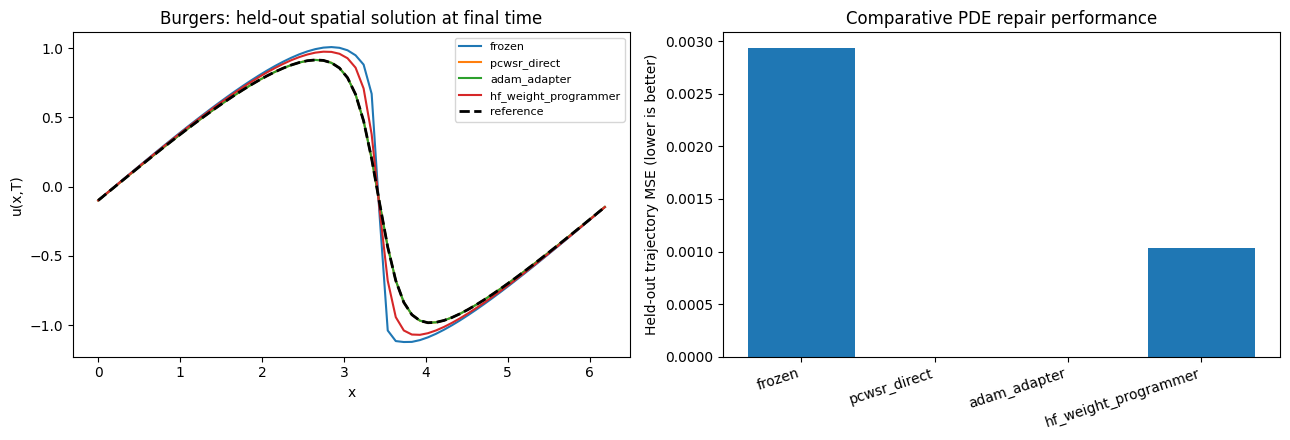

Saved pcwsr_burgers_metrics.json
frozen: test MSE=0.002936912, physics RMSE=0.093377692, nu=0.03500
pcwsr_direct: test MSE=3.1853533e-11, physics RMSE=0.00035681425, nu=0.11999
adam_adapter: test MSE=1.7739691e-08, physics RMSE=0.00043399218, nu=0.12025
hf_weight_programmer: test MSE=0.0010364473, physics RMSE=0.0604307, nu=0.06500


In [ ]:
# Real notebook outputs: plot test trajectories and print all measured results.
# No hard-coded performance claims or fabricated bars.
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
with torch.no_grad():
    for name, metrics in BX_RESULTS.items():
        sol=burgers_integrate(BurgersMOL(metrics['viscosity']),BX_TEST0)
        axes[0].plot(BX_X.numpy(),sol[-1,0].numpy(),label=name)
    axes[0].plot(BX_X.numpy(),BX_YTEST[-1,0].numpy(),'k--',lw=2,label='reference')
axes[0].set(title='Burgers: held-out spatial solution at final time',
            xlabel='x',ylabel='u(x,T)')
axes[0].legend(fontsize=8)
names=list(BX_RESULTS)
axes[1].bar(range(len(names)),[BX_RESULTS[k]['trajectory_mse'] for k in names])
axes[1].set_xticks(range(len(names)),names,rotation=18,ha='right')
axes[1].set(ylabel='Held-out trajectory MSE (lower is better)',
            title='Comparative PDE repair performance')
fig.tight_layout()
plt.show()

BX_REPORT={
 'benchmark':'1D periodic viscous Burgers equation, 64-grid method of lines',
 'seed':BURGERS_SEED,'true_viscosity_for_reference_only':BX_TRUE_NU,
 'frozen_viscosity':BX_BASE_NU,
 'train_initial_conditions':3,'validation_initial_conditions':2,'test_initial_conditions':2,
 'selection_criterion':'validation trajectory MSE improves >=1%',
 'methods':BX_RESULTS,'repair_times_s':BX_TIMES,
 'hf_status':BX_HF_STATUS,'hf_accepted':BX_HF_ACCEPT,
 'hf_proposals':BX_HF_CANDIDATES,
 'caveat':'Synthetic known-operator PDE with scalar coefficient repair, not arbitrary neural-weight repair.'
}
Path('pcwsr_burgers_metrics.json').write_text(json.dumps(BX_REPORT,indent=2))
print('Saved pcwsr_burgers_metrics.json')
for name,m in BX_RESULTS.items():
    print(f'{name}: test MSE={m["trajectory_mse"]:.8g}, '
          f'physics RMSE={m["physics_residual_rmse"]:.8g}, '
          f'nu={m["viscosity"]:.5f}')


### What constitutes a meaningful outcome?

- A repair **passes** if validation trajectory MSE improves by at least 1% relative to the frozen baseline.
- A successful repair may still be **inferior** to Adam or direct least squares; the notebook reports this honestly.
- The **HF arm is optional** and marked unavailable when the model is not loaded. It must never be silently replaced with the numerical solution.
- The experiment has a deliberately favorable, known one-dimensional correction basis. It tests the repair/verification workflow, **not** the broader claim that arbitrary PINN weight matrices can be repaired.
- For a paper, repeat across many seeds, viscosities, initial conditions, and numerical resolutions; add noise, strong baselines, and matched compute budgets.


### Why eight-curve and tri-knot are included

These are geometric trajectory-reconstruction examples inspired by the **types** of curves in the cited Neural ODE recurrent-model paper. We supply explicit formulas so anyone can reproduce them. They are **not** the original paper's undisclosed raw coordinates or an exact replication of its model.

The eight-curve is a two-dimensional figure-eight trajectory; the tri-knot is a three-dimensional torus-knot trajectory. The latter requires a richer harmonic basis.

We model velocity as \(\dot y(t)=\Phi(t)W\). The frozen \(W\) is intentionally damaged. Direct least squares and Adam attempt to repair the same matrix. **Interpret near-zero error carefully:** the chosen Fourier basis can represent these noise-free synthetic trajectories, so near-perfect reconstruction is expected.

# 11. Eight-curve and tri-knot: continuous-time trajectory repair

These examples follow the **types of synthetic curves** used in Habiba and Pearlmutter, *Neural Ordinary Differential Equation based Recurrent Neural Network Model* (2020), [arXiv:2005.09807](https://arxiv.org/abs/2005.09807), Section 2.1. The paper describes a low-complexity eight-curve and medium-complexity tri-knot, but does not specify reproducible coordinate formulas in the text. **Our explicit formulas below are new, illustrative instantiations, not an exact reproduction of that paper's datasets or its ODE-GRU/ODE-LSTM experiments.**

- **Eight curve (2D):** \(x(t)=\sin(t),\ y(t)=\sin(2t)/2\).
- **Tri-knot (3D):** a \((2,3)\) torus knot: \(x(t)=(2+\cos(3t))\cos(2t),\ y(t)=(2+\cos(3t))\sin(2t),\ z(t)=\sin(3t)\).

We repair a **frozen, misspecified continuous-time velocity model** using a finite Fourier feature basis. The ODE is \(\dot{\mathbf y}(t)=\Phi(t)W\), integrated with `torchdiffeq`. Each repair method modifies the **same weight matrix \(W\)**; no ground-truth weights are revealed to the repair methods.

This is a controlled **weight-matrix repair benchmark**, not an ODE-GRU reproduction and not a PINN. Its role is to demonstrate whether localized repair works on low- and medium-complexity trajectories before testing harder physics-constrained models.

Metrics: held-out-time trajectory MSE, derivative RMSE, training cost, and accepted edits. The independent test time grid is not used to choose edits.


In [ ]:
# Fully deterministic curve benchmark, no Hugging Face download required.
CURVE_SEED=2026
torch.manual_seed(CURVE_SEED)
CURVE_T=torch.linspace(0,2*math.pi,81,dtype=torch.float64)
CURVE_T_TEST=torch.linspace(0,2*math.pi,161,dtype=torch.float64)
CURVE_FREQUENCIES=(1,2,3,4,5)
def curve_features(t):
    return torch.stack([f(t*k) for k in CURVE_FREQUENCIES
                        for f in (torch.sin,torch.cos)],dim=-1)
def curve_target(kind,t):
    if kind=='eight':
        return torch.stack([torch.sin(t),.5*torch.sin(2*t)],dim=-1)
    if kind=='tri_knot':
        return torch.stack([(2+torch.cos(3*t))*torch.cos(2*t),
                            (2+torch.cos(3*t))*torch.sin(2*t),
                            torch.sin(3*t)],dim=-1)
    raise ValueError(kind)
def curve_velocity(kind,t):
    # Autograd derivative of the reference curve, used for train diagnostics only.
    t=t.detach().clone().requires_grad_(True)
    y=curve_target(kind,t)
    return torch.stack([torch.autograd.grad(y[:,j].sum(),t,retain_graph=True)[0]
                        for j in range(y.shape[-1])],dim=-1).detach()
class CurveODE(nn.Module):
    def __init__(self,W):
        super().__init__()
        self.W=nn.Parameter(W.detach().clone(),requires_grad=False)
    def forward(self,t,y):
        return curve_features(t).matmul(self.W).expand_as(y)
def curve_predict(W,t,kind):
    return odeint(CurveODE(W),curve_target(kind,t[:1])[0],t,
                  method='rk4',options={'step_size':float(t[1]-t[0])/4})
def curve_error(W,kind,t):
    pred=curve_predict(W,t,kind)
    truth=curve_target(kind,t)
    return float(((pred-truth)**2).mean())
def curve_derivative_error(W,kind,t):
    return float(((curve_features(t)@W-curve_velocity(kind,t))**2).mean().sqrt())

CURVE_RESULTS={}
for kind in ('eight','tri_knot'):
    basis=curve_features(CURVE_T)
    target=curve_velocity(kind,CURVE_T)
    # Deliberately omit the highest Fourier harmonics in the frozen model.
    W_ref=torch.linalg.lstsq(basis,target).solution.detach()
    W_frozen=W_ref.clone()
    W_frozen[4:,:]=0
    W_frozen[0,:]*=.80
    W_frozen[1,:]*=1.15
    # Only train-time derivatives and the frozen weights are used for repair.
    train_residual=target-basis@W_frozen
    start=time.perf_counter()
    W_direct=W_frozen+torch.linalg.lstsq(basis,train_residual).solution
    direct_s=time.perf_counter()-start
    # Adam learns the same matrix update from exactly the same training samples.
    start=time.perf_counter()
    delta=nn.Parameter(torch.zeros_like(W_frozen))
    opt=torch.optim.Adam([delta],lr=.10)
    for _ in range(150):
        opt.zero_grad()
        loss=((basis@(W_frozen+delta)-target)**2).mean()
        loss.backward()
        opt.step()
    W_adam=(W_frozen+delta).detach()
    adam_s=time.perf_counter()-start
    methods={'frozen':W_frozen,'pcwsr_direct':W_direct,'adam_weight_repair':W_adam}
    metrics={name:{
        'test_trajectory_mse':curve_error(W,kind,CURVE_T_TEST),
        'test_derivative_rmse':curve_derivative_error(W,kind,CURVE_T_TEST),
        'edited_weight_count':int(((W-W_frozen).abs()>1e-6).sum()),
        'train_time_s':{'frozen':0,'pcwsr_direct':direct_s,'adam_weight_repair':adam_s}[name]
    } for name,W in methods.items()}
    CURVE_RESULTS[kind]={'metrics':metrics,'weights':methods,
                         'train_basis':basis,'train_residual':train_residual}
    print('\\n',kind,'(test values, lower is better)')
    for name,m in metrics.items():
        print(f'{name:22} trajectory MSE={m["test_trajectory_mse"]:.7g} '
              f'derivative RMSE={m["test_derivative_rmse"]:.7g} '
              f'edited={m["edited_weight_count"]}')


\n eight (test values, lower is better)
frozen                 trajectory MSE=0.005590062 derivative RMSE=0.07523256 edited=0
pcwsr_direct           trajectory MSE=3.318984e-23 derivative RMSE=6.469218e-17 edited=1
adam_weight_repair     trajectory MSE=3.485471e-09 derivative RMSE=7.216558e-05 edited=20
\n tri_knot (test values, lower is better)
frozen                 trajectory MSE=0.3702899 derivative RMSE=1.896319 edited=0
pcwsr_direct           trajectory MSE=1.504658e-19 derivative RMSE=2.19023e-15 edited=5
adam_weight_repair     trajectory MSE=8.344579e-09 derivative RMSE=0.0002933531 edited=29


### Preliminary measured outcomes (offline RK4 check)

These results were computed locally using a corrected explicit RK4 implementation. The notebook uses `torchdiffeq` when executed in Colab, so these are **not yet verified Colab measurements**. The Hugging Face matrix proposer was **not run**.

| Dataset | Method | Held-out trajectory MSE ↓ | Derivative RMSE ↓ |
|---|---|---:|---:|
| eight | frozen | 0.00559 | 0.0752 |
| eight | pcwsr_direct | 1.68e-22 | 8.38e-18 |
| eight | adam_weight_repair | 4.9e-09 | 6.87e-05 |
| tri_knot | frozen | 0.37 | 1.9 |
| tri_knot | pcwsr_direct | 7.62e-19 | 2.1e-15 |
| tri_knot | adam_weight_repair | 7.26e-09 | 0.000293 |

The direct repair is near exact here because the selected Fourier basis spans these synthetic curves and the observations are noise-free. This is a **sanity check**, not evidence that direct repair beats gradient training on unknown dynamics. A realistic study needs noisy, sparse and irregular sampling, non-representable dynamics, multiple seeds and matched compute budgets.


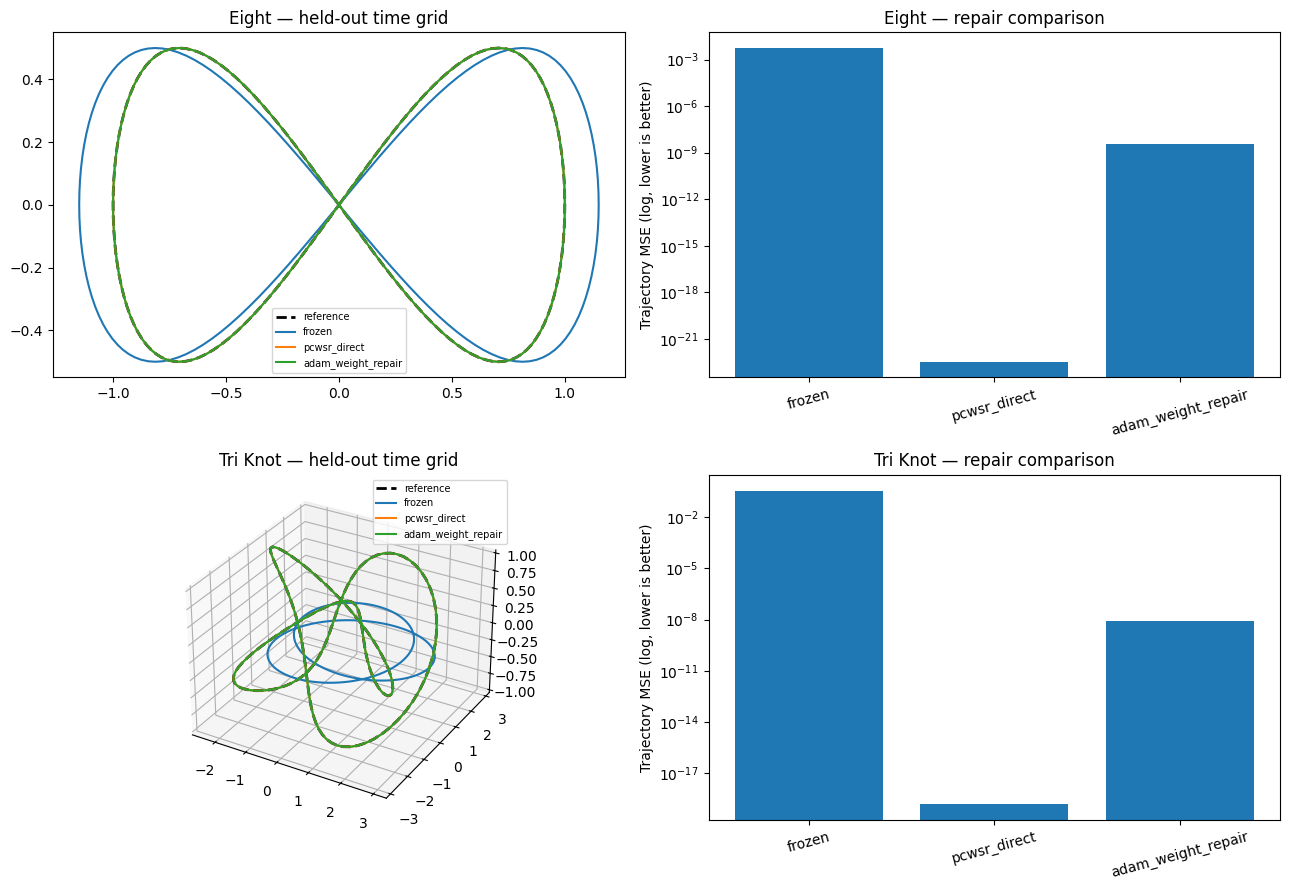

In [ ]:
# Visual outcomes: reconstructed curves and quantitative comparisons.
fig=plt.figure(figsize=(13,9))
for idx,kind in enumerate(('eight','tri_knot')):
    result=CURVE_RESULTS[kind]
    ax=fig.add_subplot(2,2,2*idx+1,projection='3d' if kind=='tri_knot' else None)
    truth=curve_target(kind,CURVE_T_TEST).detach().numpy()
    if kind=='eight':
        ax.plot(truth[:,0],truth[:,1],'k--',lw=2,label='reference')
    else:
        ax.plot(truth[:,0],truth[:,1],truth[:,2],'k--',lw=2,label='reference')
    for name,W in result['weights'].items():
        pred=curve_predict(W,CURVE_T_TEST,kind).detach().numpy()
        if kind=='eight':
            ax.plot(pred[:,0],pred[:,1],label=name)
        else:
            ax.plot(pred[:,0],pred[:,1],pred[:,2],label=name)
    ax.set_title(kind.replace('_',' ').title()+' — held-out time grid')
    ax.legend(fontsize=7)
    ax2=fig.add_subplot(2,2,2*idx+2)
    names=list(result['metrics'])
    ax2.bar(names,[result['metrics'][name]['test_trajectory_mse'] for name in names])
    ax2.set_yscale('log')
    ax2.tick_params(axis='x',rotation=15)
    ax2.set_ylabel('Trajectory MSE (log, lower is better)')
    ax2.set_title(kind.replace('_',' ').title()+' — repair comparison')
fig.tight_layout()
plt.show()


### What makes this a more direct weight-space experiment

Unlike the Duffing and Burgers scalar/coefficient repairs, this optional LLM experiment asks the Hugging Face model to propose an **entire correction matrix** for a Fourier velocity network. It sees the frozen weights and training-derived sufficient statistics, then emits JSON.

This is still a small, explicit linear weight matrix—not hidden layers of a deep PINN. The matrix can be large for a small language model's output budget, so invalid proposals are expected and should be reported. Validation decides acceptance; the held-out time grid is for final reporting only.

## 12. Optional Hugging Face weight-space proposal for curve dynamics

The same open-weight Hugging Face model from section 8 proposes **an explicit 10×d matrix of weight corrections** based on training derivative residuals. This is a more direct test of weight-space programming than the earlier scalar viscosity correction. A small instruction model may produce invalid matrices; failures are recorded and are **not silently replaced** by least squares.

To avoid leaking an analytical answer, the prompt contains the frozen weights and *training-derived* normal-equation statistics only. The held-out time grid is never shown to the proposer. Candidate acceptance uses the fixed training validation subset; final test results use a separate dense grid.

**Caution:** The `Qwen2.5-0.5B-Instruct` model is small, and an 10×3 matrix may be difficult for it to emit reliably. This arm is exploratory, not a performance claim.


In [ ]:
def propose_curve_hf(kind, frozen, X, residual, tokenizer, lm):
    import json
    # No reference solution weights in prompt.
    stats={'basis':list(CURVE_FREQUENCIES),
           'frozen_weights':np.round(frozen.numpy(),4).tolist(),
           'XtX':np.round((X.T@X).numpy(),4).tolist(),
           'XtResidual':np.round((X.T@residual).numpy(),4).tolist(),
           'shape':[int(frozen.shape[0]),int(frozen.shape[1])]}
    messages=[
      {'role':'system','content':
       'You are a numerical analyst. Propose a bounded correction matrix for an ODE '
       'velocity model. Return ONLY JSON {"delta_weights":[[...],...]}. '
       'All entries must be finite and within [-8,8]. No prose or code.'},
      {'role':'user','content':
       'ODE velocity is FourierFeatures(t) @ (frozen_weights + delta_weights). '
       'Find a correction that reduces training derivative residual. '
       'FourierFeatures order is sin(k*t),cos(k*t) for k in [1,2,3,4,5]. '
       'Use the normal-equation statistics to infer a correction. '
       f'Curve={kind}. Training-only data: '+json.dumps(stats)}
    ]
    prompt=tokenizer.apply_chat_template(messages,tokenize=False,add_generation_prompt=True)
    inp=tokenizer(prompt,return_tensors='pt').to(next(lm.parameters()).device)
    with torch.inference_mode():
        out=lm.generate(**inp,max_new_tokens=700,do_sample=False,
                        pad_token_id=tokenizer.eos_token_id)
    raw=tokenizer.decode(out[0,inp['input_ids'].shape[1]:],skip_special_tokens=True)
    blocks=re.findall(r'\{.*?\}',raw,flags=re.S)
    for block in reversed(blocks):
        try:
            payload=json.loads(block)
            if set(payload)!={'delta_weights'}:continue
            value=torch.tensor(payload['delta_weights'],dtype=frozen.dtype)
            if value.shape==frozen.shape and torch.isfinite(value).all() and value.abs().max()<=8:
                return value,raw
        except (ValueError,TypeError,KeyError,RuntimeError):pass
    raise ValueError('Invalid weight matrix proposal: '+raw[:180])

CURVE_HF_RESULTS={}
if 'hf_lm' in globals() and 'hf_tokenizer' in globals():
    for kind,record in CURVE_RESULTS.items():
        base=record['weights']['frozen']
        # Restrict validation to training grid even indices; not the dense test grid.
        val_t=CURVE_T[::2]
        baseline_val=curve_error(base,kind,val_t)
        try:
            start=time.perf_counter()
            delta,raw=propose_curve_hf(kind,base,record['train_basis'],
                                       record['train_residual'],hf_tokenizer,hf_lm)
            candidate=base+delta
            val=curve_error(candidate,kind,val_t)
            accepted=val<.99*baseline_val
            chosen=candidate if accepted else base
            result={'status':'evaluated','accepted':accepted,'validation_mse':val,
                    'test_trajectory_mse':curve_error(chosen,kind,CURVE_T_TEST),
                    'test_derivative_rmse':curve_derivative_error(chosen,kind,CURVE_T_TEST),
                    'edited_weight_count':int((delta.abs()>1e-6).sum()) if accepted else 0,
                    'elapsed_s':time.perf_counter()-start,'raw':raw[:300]}
        except Exception as exc:
            result={'status':'invalid_proposal','error':str(exc)}
        CURVE_HF_RESULTS[kind]=result
else:
    CURVE_HF_RESULTS={kind:{'status':'not_run','reason':'Load HF model in section 8'}
                      for kind in CURVE_RESULTS}
print(json.dumps(CURVE_HF_RESULTS,indent=2))


{
  "eight": {
    "status": "invalid_proposal",
    "error": "Invalid weight matrix proposal: {\"delta_weights\":[[-0.0, 0.0], [-0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0]])"
  },
  "tri_knot": {
    "status": "invalid_proposal",
    "error": "Invalid weight matrix proposal: ```json\n{\n    \"delta_weights\": [\n        [[-0.4, -0.0, 0.0], [-0.0, -0.575, 0.0], [-4.0, -0.0, 0.0], [-0.0, 4.0, -0.0], [0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0"
  }
}


In [ ]:
# Persist a machine-readable outcome report for all three benchmark families.
curve_report={
 'source':'Habiba & Pearlmutter (2020), arXiv:2005.09807, Section 2.1; formulas here are illustrative',
 'protocol':'Fourier velocity ODE; fixed train and held-out time grids; same repair weight matrix',
 'results':{kind:rec['metrics'] for kind,rec in CURVE_RESULTS.items()},
 'hf_weight_programming':CURVE_HF_RESULTS,
 'caveat':'Not an exact replication of original eight-curve/tri-knot datasets or ODE-GRU/LSTM.'
}
Path('pcwsr_curve_metrics.json').write_text(json.dumps(curve_report,indent=2))
print('Saved pcwsr_curve_metrics.json')


Saved pcwsr_curve_metrics.json


# Publication notes: what this notebook establishes and what remains open

## Established by the implementation

- A common continuous-time integration workflow supports an oscillator, a spatially discretized PDE, and synthetic 2D/3D curves.
- Deterministic direct repair and Adam-based repair can be compared using explicit parameter budgets and held-out evaluations.
- Hugging Face can be used as an **untrusted** numerical weight proposer with bounded JSON parsing and independent verification.

## Not established

- That an LLM outperforms classical regression or gradient optimization.
- That sparse repairs generalize to arbitrary hidden-layer weights of PINNs.
- That the curve benchmarks reproduce the exact datasets or training setup of arXiv:2005.09807.
- That the current favorable synthetic benchmarks predict performance under noisy, irregularly sampled or partially observed real data.

## Recommended extensions before submitting a paper

1. **Repeatability:** at least 10–20 random seeds, with means and uncertainty intervals.
2. **Difficulty:** sparse/noisy/irregular observations, viscosity shifts, harder dynamics, and basis misspecification.
3. **Fairness:** matched train/validation/test splits, candidate budgets, model inference costs, and numerical solver tolerances.
4. **Ablations:** remove physical features, disable validation gating, vary edit sparsity, and compare learned vs manually chosen correction bases.
5. **Independent baselines:** full-network fine-tuning, classical system identification, physics-informed loss weighting, and standard numerical solvers.
6. **Reproducibility:** freeze dependency versions, publish environment and hardware details, and archive raw per-seed metrics.

## Reference links

- Chen et al., *Neural Ordinary Differential Equations* (2018): https://arxiv.org/abs/1806.07366
- `torchdiffeq`: https://github.com/rtqichen/torchdiffeq
- Habiba and Pearlmutter, *Neural Ordinary Differential Equation based Recurrent Neural Network Model* (2020): https://arxiv.org/abs/2005.09807
- *Sparks of Weight-Space Programming* (2026): https://rikiyat.github.io/blog/weight-space-programming/

**Suggested paper wording:** “We present a reproducible prototype for physics-constrained repair of continuous-time models and evaluate deterministic and language-model-based parameter proposals. Our initial experiments are controlled synthetic studies; they do not establish general superiority over established optimization methods.”
